<a href="https://colab.research.google.com/github/Clinton1029/Auto-MPG-Prediction-/blob/main/group_(1)_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## QUESTION 1: Applied Analytics Process and Problem Formulation

### 1(a) Stakeholder, Decision and Analytical Question

**Stakeholder:**

The main stakeholder is an automobile manufacturer or car
dealer interested in understanding and estimating the fuel
efficiency of different vehicles.

**Decision to be Supported:**

The analysis will help automobile manufacturers and car
dealers understand how vehicle characteristics influence
fuel efficiency. It can support decisions when designing,
selecting or recommending vehicles with better fuel economy.

**Analytical Question:**

To what extent can vehicle characteristics such as
cylinders, displacement, horsepower, weight, acceleration,
model year and origin be used to predict a vehicle's fuel
efficiency (miles per gallon)?

### 1(b) Target Variable, Predictors and Learning Task

**Response (Target) Variable:**

The target variable is `mpg` (miles per gallon), which
measures the fuel efficiency of a vehicle.

**Predictor Variables:**

The proposed predictors are:

1. Cylinders – Number of engine cylinders.
2. Displacement – Engine displacement in cubic inches.
3. Horsepower – Engine power output.
4. Weight – Total vehicle weight in pounds.
5. Acceleration – Vehicle acceleration time in seconds.
6. Model year – Year of vehicle manufacture.
7. Origin – Geographical origin of the vehicle.

The `car name` variable will be excluded because it is
an identifier containing vehicle model names rather than
a direct numerical vehicle specification.

**Learning Task:**

The problem is a supervised machine learning regression
task because the objective is to predict a continuous
numerical value (mpg) using vehicle characteristics.

**Measurable Performance Criterion:**

The model will be evaluated using Mean Absolute Error
(MAE), Root Mean Squared Error (RMSE) and R-squared (R²).

The model will be considered practically useful if it
achieves a lower test RMSE than the baseline model that
predicts the mean MPG of the training data, together with
a reasonably high test R-squared value.

### 1(c) Six Stages of the Applied Analytics Process

The Auto MPG prediction problem follows six stages of the
Applied Analytics Process as described below.

**1. Problem/Business Understanding**

Activity:
Identify the need to understand and predict vehicle fuel
efficiency using vehicle characteristics.

Expected Output:
A clearly defined analytical problem, stakeholder and
objective of predicting miles per gallon (mpg).

**2. Data Understanding**

Activity:
Load and examine the Auto MPG dataset to understand its
structure, variables, data types, distributions and data
quality issues.

Expected Output:
An understanding of the dataset, including its variables,
missing values, relationships and possible data quality
problems.

**3. Data Preparation**

Activity:
Clean the dataset by handling missing horsepower values,
checking duplicates, correcting data types and selecting
appropriate predictors. Treat origin as categorical and
exclude car name from the introductory regression model.

Expected Output:
A clean and appropriately prepared dataset suitable for
exploratory analysis and regression modelling.

**4. Modelling**

Activity:
Develop a multiple linear regression model using selected
vehicle characteristics to predict MPG.

Expected Output:
A fitted regression model that estimates vehicle fuel
efficiency from the selected predictors.

**5. Evaluation**

Activity:
Evaluate model performance using test data and metrics
such as MAE, RMSE and R-squared. Compare the model against
a baseline prediction.

Expected Output:
Performance results showing the accuracy and limitations
of the regression model.

**6. Communication/Deployment**

Activity:
Present the findings, model performance, visualizations
and recommendations to automobile manufacturers or car
dealers. The model can be used to estimate the fuel
efficiency of vehicles with available specifications.

Expected Output:
A clear analytical report and a usable prediction model
that supports vehicle selection and design decisions.

### 1(d) Limitation or Risk

One limitation is that the Auto MPG dataset contains
historical vehicle information.
Consequently, the model may not accurately predict the
fuel efficiency of modern vehicles because vehicle
technology and engine designs have changed over time.

If model evaluation reveals high prediction errors,
the analyst may return to the data understanding stage
to investigate the dataset or to the modelling stage
to improve predictor selection and model performance.

## QUESTION 2: IMPORTATION, INSPECTION AND DATA DICTIONARY

This section involves importing the necessary Python libraries, loading the Auto MPG dataset, inspecting its structure and preparing a data dictionary. The aim is to understand the dataset and identify the variables that will be used to predict vehicle fuel efficiency (mpg).

### 2(a) Importation of Python Libraries

The following Python libraries are imported to support
data manipulation, statistical analysis, visualization
and regression modelling in the Auto MPG project.

In [2]:
# Import os to manage file paths
import os

# Import pandas for data manipulation
import pandas as pd

# Import numpy for numerical computations
import numpy as np

# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Import seaborn for statistical visualization
import seaborn as sns

# Import train_test_split to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Import ColumnTransformer and TransformedTargetRegressor for preprocessing
# and transforming the target variable
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

# Import Pipeline to combine preprocessing and modelling steps
from sklearn.pipeline import Pipeline

# Import SimpleImputer to handle missing values
from sklearn.impute import SimpleImputer

# Import encoders and scalers for feature preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# Import LinearRegression to build the regression model
from sklearn.linear_model import LinearRegression

# Import DummyRegressor to create a baseline model
from sklearn.dummy import DummyRegressor

# Import metrics to evaluate regression model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Configure Display Settings and Visualization Theme

Pandas display settings are adjusted to show up to 100 rows and display floating-point numbers to three decimal places for better readability. Seaborn is also configured to use the `whitegrid` theme to improve the appearance and readability of visualizations.

In [3]:
# Set Pandas to display floating-point numbers to three decimal places
# This improves the readability of numerical outputs in tables
pd.set_option("display.max_row", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Set Seaborn's visualization theme to whitegrid
# This adds a white background with grid lines to improve plot readability
sns.set_theme(style="whitegrid")

### 2(b) Dataset Importation and Initial Inspection

The Auto MPG dataset is imported using the Pandas library.
Initial inspection is conducted to understand the dataset's
structure, dimensions, variables, data types and sample records.

The inspection uses head(), tail(), sample(), shape,
columns, dtypes and info() as required.

In [4]:
# Define the file path where the Auto MPG dataset is stored
file = "/content/auto-mpg.csv"

# Check whether the specified file exists
if os.path.exists(file):

    # Display a confirmation message if the file is found
    print("file found!")

    # Load the CSV file into a Pandas DataFrame
    df = pd.read_csv(file)

# Execute this block if the specified file does not exist
else:

    # Display a message indicating that the file was not found
    print("file not found!")

file found!


#### 2.b.1 Display the First Five Records

The `head()` function displays the first five observations to provide an initial view of the dataset.

In [4]:
# Display the first five records of the dataset
df.head(100)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.000,8,307.000,130,3504,12.000,70,1,chevrolet chevelle malibu
1,15.000,8,350.000,165,3693,11.500,70,1,buick skylark 320
2,18.000,8,318.000,150,3436,11.000,70,1,plymouth satellite
3,16.000,8,304.000,150,3433,12.000,70,1,amc rebel sst
4,17.000,8,302.000,140,3449,10.500,70,1,ford torino
5,15.000,8,429.000,198,4341,10.000,70,1,ford galaxie 500
6,14.000,8,454.000,220,4354,9.000,70,1,chevrolet impala
7,14.000,8,440.000,215,4312,8.500,70,1,plymouth fury iii
8,14.000,8,455.000,225,4425,10.000,70,1,pontiac catalina
9,15.000,8,390.000,190,3850,8.500,70,1,amc ambassador dpl


#### 2.b.2 Display the Last Five Records

The `tail()` function displays the last five observations in the dataset.

In [5]:
# Display the last five records of the dataset
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.000,4,140.000,86,2790,15.600,82,1,ford mustang gl
394,44.000,4,97.000,52,2130,24.600,82,2,vw pickup
395,32.000,4,135.000,84,2295,11.600,82,1,dodge rampage
396,28.000,4,120.000,79,2625,18.600,82,1,ford ranger
397,31.000,4,119.000,82,2720,19.400,82,1,chevy s-10


#### 2.b.3 Display a Random Sample

The `sample()` function selects five random observations to provide a representative view of the dataset.

In [6]:
# Display five randomly selected records
df.sample(5, random_state=42)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
198,33.000,4,91.000,53,1795,17.400,76,3,honda civic
396,28.000,4,120.000,79,2625,18.600,82,1,ford ranger
33,19.000,6,232.000,100,2634,13.000,71,1,amc gremlin
208,13.000,8,318.000,150,3940,13.200,76,1,plymouth volare premier v8
93,14.000,8,318.000,150,4237,14.500,73,1,plymouth fury gran sedan


#### 2.b.4 Display Column Names

The `columns.tolist()` function displays all variable names in the dataset as a Python list.

In [7]:
# Retrieve and display all column names in the dataset as a Python list
df.columns.tolist()

['mpg',
 'cylinders',
 'displacement',
 'horsepower',
 'weight',
 'acceleration',
 'model year',
 'origin',
 'car name']

#### 2.b.5 Check Dataset Dimensions

The `shape` attribute displays the total number of rows and columns in the dataset.

In [ ]:
# Display the number of rows and columns in the dataset
# The output is a tuple: (number of rows, number of columns)
df.shape

(398, 9)

#### 2.b.6 Check Data Types

The `dtypes` attribute identifies the data type of each variable, helping to distinguish numerical and non-numerical columns.

In [ ]:
# Display the data type of each column in the dataset
# This helps identify numerical, categorical, and text columns
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower          str
weight            int64
acceleration    float64
model year        int64
origin            int64
car name            str
dtype: object

#### 2.b.7 Display Dataset Information

The `info()` function provides a summary of the dataset, including column names, non-null values, data types and memory usage.

In [9]:
# Display a concise summary of the DataFrame, including column names,
# number of non-null entries, data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


### 2(c). Prepare a Data Dictionary

A data dictionary describes each original variable in the Auto MPG dataset. It includes the variable name, meaning, data type or measurement scale, units of measurement and role in the regression analysis.

In [10]:
# Create a data dictionary containing all original dataset variables
data_dictionary = {
    'mpg': {
        'Meaning': 'Vehicle fuel efficiency',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Miles per gallon',
        'Role': 'Target'
    },

    'cylinders': {
        'Meaning': 'Number of engine cylinders',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Count',
        'Role': 'Predictor'
    },

    'displacement': {
        'Meaning': 'Engine displacement',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Cubic inches',
        'Role': 'Predictor'
    },

    'horsepower': {
        'Meaning': 'Engine power output',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Horsepower',
        'Role': 'Predictor'
    },

    'weight': {
        'Meaning': 'Vehicle weight',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Pounds',
        'Role': 'Predictor'
    },

    'acceleration': {
        'Meaning': 'Time taken by the vehicle to accelerate',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Ratio',
        'Unit': 'Seconds',
        'Role': 'Predictor'
    },

    'model year': {
        'Meaning': 'Vehicle manufacturing year',
        'Data Type': 'Numerical',
        'Measurement Scale': 'Interval',
        'Unit': 'Year',
        'Role': 'Predictor'
    },

    'origin': {
        'Meaning': 'Geographical origin of the vehicle',
        'Data Type': 'Categorical',
        'Measurement Scale': 'Nominal',
        'Unit': 'Category code',
        'Role': 'Predictor'
    },

    'car name': {
        'Meaning': 'Name or model identification of the vehicle',
        'Data Type': 'Text',
        'Measurement Scale': 'Nominal',
        'Unit': 'Not applicable',
        'Role': 'Identifier'
    }
}

print("Convert Data Dictionary into a pandas dataframe")

#create a dataframe
data = pd.DataFrame(data_dictionary)

#Display the dataframe
data.head()




Convert Data Dictionary into a pandas dataframe


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
Meaning,Vehicle fuel efficiency,Number of engine cylinders,Engine displacement,Engine power output,Vehicle weight,Time taken by the vehicle to accelerate,Vehicle manufacturing year,Geographical origin of the vehicle,Name or model identification of the vehicle
Data Type,Numerical,Numerical,Numerical,Numerical,Numerical,Numerical,Numerical,Categorical,Text
Measurement Scale,Ratio,Ratio,Ratio,Ratio,Ratio,Ratio,Interval,Nominal,Nominal
Unit,Miles per gallon,Count,Cubic inches,Horsepower,Pounds,Seconds,Year,Category code,Not applicable
Role,Target,Predictor,Predictor,Predictor,Predictor,Predictor,Predictor,Predictor,Identifier


#### 2.c.1 Check Unique Values

The `nunique()` function counts the number of distinct values in each column, while `sort_values()` arranges the counts in ascending order to identify columns with fewer or more unique values.

In [ ]:
# Count the number of unique values in each column
# Sort the counts in ascending order to identify columns
# with fewer or more distinct values
df.nunique().sort_values()

origin            3
cylinders         5
model year       13
displacement     82
horsepower       94
acceleration     95
mpg             129
car name        305
weight          351
dtype: int64

#### 2.c.2 Numerical Summary Statistics

Descriptive statistics are generated for the numerical variables, excluding origin because it represents geographical categories rather than a continuous numerical measurement.

In [ ]:
# Display descriptive statistics for numerical columns, transposed for readability
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,398.000,23.515,7.816,9.000,17.500,23.000,29.000,46.600
cylinders,398.000,5.455,1.701,3.000,4.000,4.000,8.000,8.000
displacement,398.000,193.426,104.270,68.000,104.250,148.500,262.000,455.000
weight,398.000,"2,970.425",846.842,"1,613.000","2,223.750","2,803.500","3,608.000","5,140.000"
acceleration,398.000,15.568,2.758,8.000,13.825,15.500,17.175,24.800
model year,398.000,76.010,3.698,70.000,73.000,76.000,79.000,82.000
origin,398.000,1.573,0.802,1.000,1.000,1.000,2.000,3.000


###### Interpratation
* if median(50%) is  < mean this shows huge values are pulling the mean up impling right skewness

* if median(50%) is > mean this shows low values are pulling mean down which implies  left-skewness

* if median is approximately close to mean or equal to implies a symetrical data

* std shows how values are spread from the mean

## QUESTION 3: DATA QUALITY ASSESSMENT AND INITIAL CLEANING [15 MARKS]

This section assesses the quality of the Auto MPG dataset by identifying missing values, placeholder values, blank strings, incorrect data types and other data quality issues. The aim is to identify problems that may affect the accuracy and reliability of the regression analysis.

#### 3(a). Identify Missing Values

The number of missing values in each column is examined to identify variables with incomplete observations.

In [11]:
# Count the missing values in each column
df.isna().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
origin,0
car name,0


##### Interpration

The `horsepower` column was initially stored as an object instead of a numeric data type because it contained six `?` placeholder values. When `df.isna().sum()` was executed, it did not identify these values as missing because they were stored as text. Therefore, they needed to be converted to `NaN` before the missing values could be properly detected and handled.

#### 3.a.2 Convert Horsepower to Numeric Data Type

The `horsepower` column is converted from an object (text) data type to a numeric data type. The `errors='coerce'` parameter converts invalid entries, such as the six `?` placeholders, into `NaN` so they can be identified as missing values.

In [13]:
# Convert horsepower from object (text) to numeric data type.
df["horsepower"] = pd.to_numeric(df["horsepower"], errors='coerce')

#### 3.a.3 Verify Missing Values

The `isna().sum()` function is used to verify that the six invalid `horsepower` entries have been successfully converted into missing values (`NaN`).

In [14]:
# Count the missing values in each column
df.isna().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model year,0
origin,0
car name,0


##### The data have 6 missing values in the Horsepower Column

### 3.a.4 Calculate Percentage of Missing Values

The percentage of missing values in each column is calculated to determine the extent of missing data relative to the total number of observations.

In [18]:
# Calculate the percentage of missing values in each column
missing = (df.isna().sum() / len(df)) * 100

# Display the missing value percentages
missing

,0
mpg,0.000
cylinders,0.000
displacement,0.000
horsepower,1.508
weight,0.000
acceleration,0.000
model year,0.000
origin,0.000
car name,0.000


### Missing Values Identified

The assessment revealed that the `horsepower` column contains 6 missing values, representing approximately **1.508%** of the total observations.

### 3(b). Check Duplicate Records, Missing Target Values and Identifiers

This subsection examines the dataset for exact duplicate records, missing values in the target variable (`mpg`) and duplicate or inappropriate identifiers. The number of affected records is identified to determine whether any records need to be removed.

#### 3.b.1 Check Exact Duplicate Records

The `duplicated()` function is used to identify records that are exact duplicates of other rows in the dataset.

In [19]:
# Display the total number of duplicate records
print(f"we have {df.duplicated().sum()} duplicates")

we have 0 duplicates


#### 3.b.2 Check Missing Target Values

The target variable is `mpg`. Missing target values are identified because records without the target cannot be used to train or evaluate the regression model.

In [16]:
# Count missing values in the target variable
print(f"We have {df["mpg"].isna().sum() } missing values in the target variable")


We have 0 missing values in the target variable


### 3.b.3 Check Duplicate Vehicle Identifiers

The `car name` column identifies vehicle models. Its duplicate values are examined to determine whether vehicle names are repeated. Repeated names are not automatically considered errors because different observations may represent vehicles of the same model.

In [17]:
# Count duplicate vehicle names
df["car name"].duplicated().sum()

np.int64(93)

###### Interpretation of Duplicate Vehicle Names

The assessment identified 93 repeated vehicle names in the `car name` column. These repetitions do not necessarily indicate errors because different records may represent vehicles of the same model. Therefore, they will not be removed. The `car name` column will also be excluded from the regression predictors because it serves as an identifier.

### 3.b.4 Description of Records Removed

No exact duplicate records or missing target (`mpg`) values were found; therefore, no records were removed. The 93 repeated vehicle names were retained because they do not necessarily represent duplicate records. The six missing `horsepower` values were also retained for handling during preprocessing (we'll impute them).

* **We have not removed any duplicaates as there are none.**

* **We'll keep our missing values as we'll impute them**

### 3(c). Identify Unusual Numerical Values Using Boxplots

Boxplots are used to identify unusual numerical values in the Auto MPG dataset. They help visualize the distribution, spread and potential outliers in numerical variables. The identified values will be examined to distinguish possible errors from legitimate extreme observations.

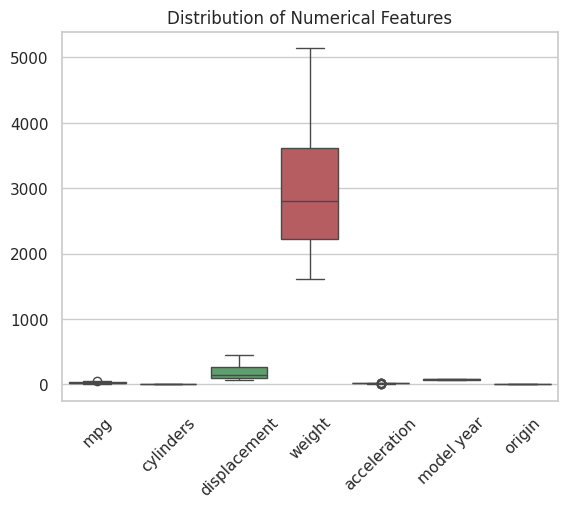

In [5]:
# Create boxplots for all numerical columns in the dataset
sns.boxplot(data=df)

# Add a descriptive title
plt.title("Distribution of Numerical Features")

# Rotate x-axis labels by 45 degrees for readability
plt.xticks(rotation=45)

# Display the boxplots
plt.show()

* **We have some outliers in some  of the features which are from extreme values from some cars**

* **we have decided to impute the missing values by simpleimputer as 1.508% We can imputation introduces minimal bias**

## QUESTION 4: DATA PARTITIONING AND EXPLORATORY DATA ANALYSIS [20 MARKS]

This section involves separating the candidate predictors (X) from the target variable (y), followed by splitting the dataset into training and testing sets. Exploratory data analysis is then performed using only the training data to understand variable distributions and relationships.

### 4(a). Define Candidate Predictors (X) and Target (y)

The target variable is `mpg`, which represents vehicle fuel efficiency. The candidate predictors include cylinders, displacement, horsepower, weight, acceleration, model year and origin.

The `car name` column is excluded because it serves as an identifier rather than a direct numerical vehicle specification. The target variable is also excluded from X to prevent data leakage.

In [11]:
# Define candidate predictors by excluding mpg and car name
features =['cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model year', 'origin', ]

**We have removed identifier which is car name**

In [12]:
# Select the predictor columns from the dataset
X = df[features]

# Select mpg as the target variable
y = df["mpg"]

In [13]:
# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**we have split our data into 80% training set and 20% test set**

In [24]:
#Display the dimension of x_train
print(f"dimension of X_train is{X_train.shape}")

dimension of X_train is(318, 7)


In [25]:
# Display the dimension of y_train
print(f"y_train has dimensions of{y_train.shape}")

y_train has dimensions of(318,)


In [26]:
# Display the dimension of y_test
print("dimension of X_test is:", X_test.shape)

dimension of X_test is: (80, 7)


In [27]:
# Display the dimension of y_test
print("dimension of y_test is:", y_test.shape)

dimension of y_test is: (80,)


### 4(b). Univariate Analysis

Univariate analysis examines individual variables in the training dataset to understand their distributions, central tendencies, spread, skewness and potential unusual values. Histograms, boxplots and frequency summaries are used for this analysis.

#### 4.b.2 Histograms of Numerical Variables

Histograms are used to examine the distributions of numerical variables. They help identify the shape of distributions, concentration of observations and possible skewness.

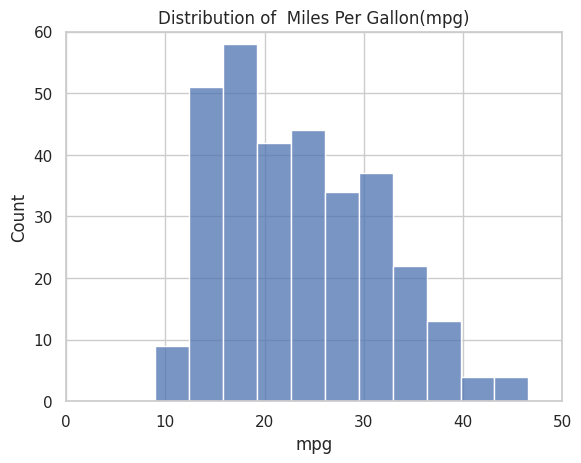

In [33]:
# Creates a histogram of the target variable y_train using Seaborn
sns.histplot(data=X_train, x=y_train)

# Adds a title to the top of the plot
plt.title("Distribution of  Miles Per Gallon(mpg)")


# Restricts the horizontal x-axis view to display values strictly between 0 and 50
plt.xlim(0, 50)

# Restricts the vertical y-axis (frequency/count) view to display counts strictly between 0 and 60
plt.ylim(0, 60)

# Renders and displays the final plot window on the screen
plt.show()


* *we have this distribution tells us how cars mpg were frequency*
* *The data is rightly skewed*

### 4.b.2.1 Distribution of Engine Displacement

A box plot is used to examine the distribution of engine displacement values in the training dataset. It displays the median, interquartile range (IQR), whiskers and potential outliers.

The visualization helps identify the typical engine displacement range, the variation in engine sizes and whether vehicles with unusually small or large engine displacements are present in the dataset.

Text(0.5, 1.0, 'Distribution of  Displacement')

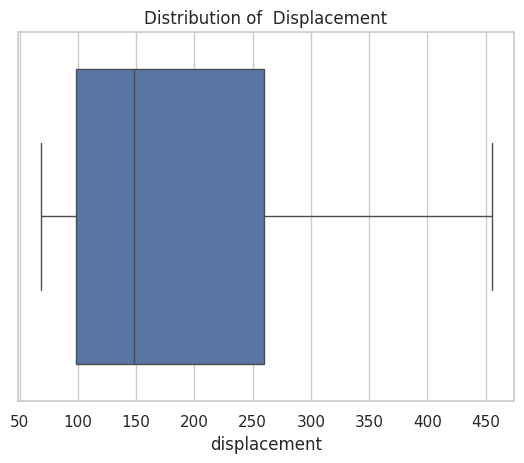

In [32]:
# Creates a horizontal box plot using the 'displacement' column from the X_train DataFrame
sns.boxplot(data=X_train, x="displacement")

# Adds a title to the top of the plot
plt.title("Distribution of  Displacement")


**Interpretation of the displacement boxplot**

-  The median displacement is about 150 cubic inches, so half of the cars have engines smaller than this therefore the data is right-skewed.
-  The box is running from about 100 (Q1) to about 260 (Q3). The middle 50% of cars therefore vary a lot in engine size from small to fairly large engines.
- The median sits closer to Q1 than to Q3 and the right whisker (reaching about 455) is much longer than the left whisker. Most cars have small to medium engines with a smaller group of cars having very large engines.
- No outliers are flagged. The largest value (about 455) is still within the upper fence.


### 4.b.2.2 Distribution of Vehicle Acceleration

A box plot is used to examine the distribution of vehicle acceleration values in the training dataset. It displays the median, interquartile range (IQR), whiskers and potential outliers.

The visualization helps identify the typical acceleration range, the spread of acceleration values and whether any vehicles have unusually high or low acceleration times. This provides insight into the variation in acceleration performance among the vehicles.

Text(0.5, 1.0, 'Distribution of  Acceleration')

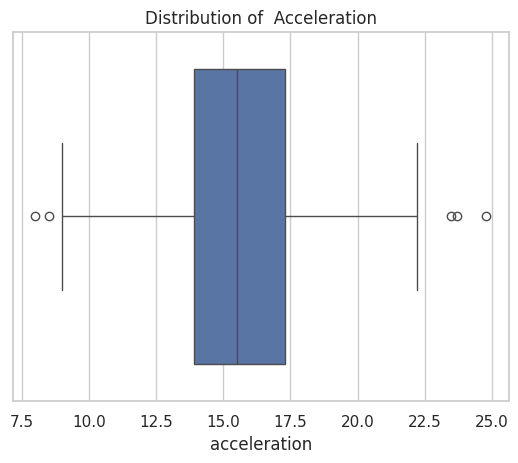

In [36]:
# Creates a horizontal box plot of the 'acceleration' column from the X_train DataFrame
# Displays the median, interquartile range (middle 50% of data), whiskers, and any outliers
sns.boxplot(data=X_train, x="acceleration")

# Adds a title at the top of the plot
plt.title("Distribution of  Acceleration")


**Interpretation of the acceleration boxplot**

- Median is about 15.5 seconds (0 to 60 mph time).
- 50% of the vehicles lie between about 13.9 and 17.3 seconds.
- **Skewness:** Approximately **symmetric.** The median is near the centre of the box and the whiskers are similar in length.
- **Outliers:** Dots appear on **both sides**: a few very quick cars about 8 to 8.5 seconds and a few very slow ones about 23.5 to 25 seconds.
-  The outliers are plausible extremes sports cars and slow economy cars so they are retained.

### 4.b.2.3 Distribution of Vehicle Horsepower

A box plot is used to examine the distribution of horsepower values among vehicles in the training dataset. It shows the median, interquartile range (IQR), whiskers and potential outliers.

The visualization helps identify the typical horsepower range, the variability in engine power and whether unusually high or low horsepower values exist. This provides an understanding of the differences in engine power across the vehicles.

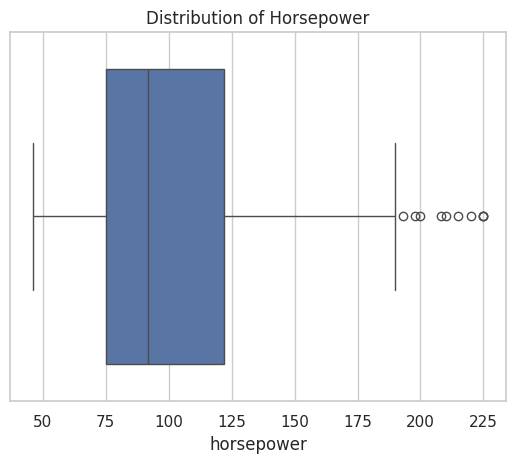

In [35]:
# Creates a horizontal box plot of the 'horsepower' column from the X_train DataFrame
# Visualizes the median, interquartile range (middle 50% of values), whiskers, and any outliers
sns.boxplot(data=X_train, x="horsepower")

# Sets the title displayed at the top of the chart
plt.title("Distribution of Horsepower")

# Renders and displays the completed figure on the screen, clearing the current plot state
plt.show()


**Interpretation of the horsepower boxplot**

- Median is about 92 hp so half of the cars produce less than this.
- The middle 50% of cars lie between about 75 hp (Q1) and 122 hp (Q3).
- **Skewness:** **Right-skewed.** The median sits closer to Q1 and the upper whisker is longer than the lower one.
- **Outliers:** Several dots lie beyond the upper fence at roughly 195 to 225 hp. They represent a few high-performance cars. Because they are genuine vehicles and not data errors they are retained.
- Most cars are low to moderate power with a small group of very powerful ones.

### 4.b.2.4 Distribution of Vehicle Weight

A box plot is used to examine the distribution of vehicle weight in the training dataset. It displays the median, interquartile range (IQR), whiskers and potential outliers.

The visualization helps identify the spread of vehicle weights, the central weight value and whether unusually heavy or light vehicles are present. It also provides insight into the variability of vehicle weights within the dataset.

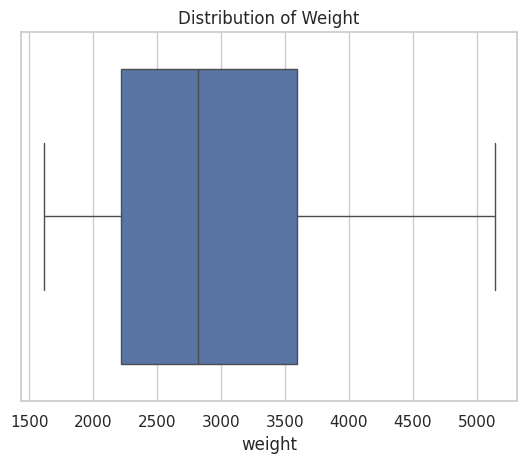

In [38]:
# Creates a horizontal box plot of the 'weight' column from the X_train DataFrame
# Shows the median, interquartile range (middle 50% of data), whiskers, and any extreme values
sns.boxplot(data=X_train, x="weight")

# Adds a descriptive title above the chart
plt.title("Distribution of Weight")

# Displays the final plot
plt.show()


###### Distribution of Weight — Key Takeaways

* **Median (~2,820):** Half of the cars weigh less than ~2,820 lbs, and half weigh more.
* **Interquartile Range (~2,220 to ~3,600):** The middle 50% of vehicles fall within a ~1,380 lb spread.
* **Right Skew:** The upper half of the box and the right whisker (extending past 5,100) are noticeably longer than the lower half (starting around 1,610), indicating a tail of heavier vehicles.
* **No Outliers:** All data points fall within the standard whisker range, so no extreme outlier capping is needed for `weight`.


### 4.b.2.5 Distribution of Vehicles by Number of Cylinders

A bar chart is used to show the frequency of vehicles with different numbers of cylinders in the training dataset. The x-axis represents the number of cylinders, while the y-axis shows the number of vehicles in each category.

This visualization helps identify the most common and least common engine configurations among the vehicles and provides insight into the distribution of engine sizes in the dataset.

Text(0.5, 0, 'Cylinders')

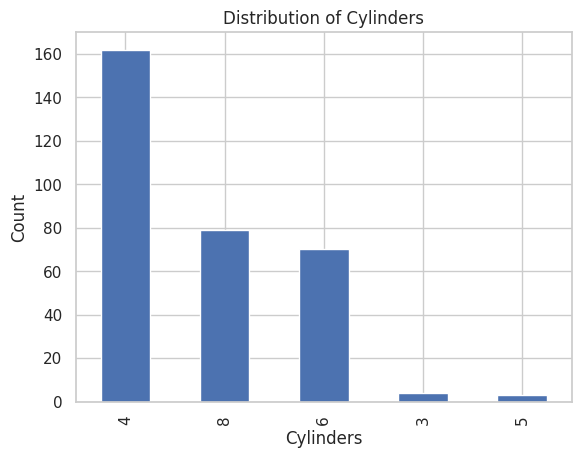

In [43]:
# Selects the 'cylinders' column, counts the frequency of each unique cylinder value,
# and plots those counts as a vertical bar chart using pandas' built-in plotting wrapper
X_train['cylinders'].value_counts().plot(kind="bar")
#Add Title
plt.title("Distribution of Cylinders")
#Add y label
plt.ylabel("Count")
#Add x label
plt.xlabel("Cylinders")


* **There were many 4 inline cylinder cars with  $\approx$  160 with the least as 5 inline cylinder cars**

### 4.b.2.6 Distribution of Cars by Origin

A pie chart is used to illustrate the distribution of vehicles according to their origin in the training dataset. The chart displays the proportion of cars from each origin category as percentages.

This visualization helps identify which origin category contributes the largest and smallest number of vehicles in the dataset and provides an overview of the geographical distribution of the cars.

Text(0.5, 1.0, 'Distribution of Car Origin')

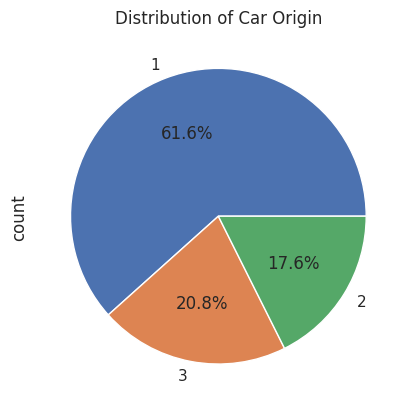

In [45]:
# Selects the 'origin' column, counts how many times each category appears,
# and plots the proportions as a pie chart with percentage labels formatted to 1 decimal place
X_train['origin'].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Distribution of Car Origin")

* **The pie chart shows the data  had cars from 1(USA) as highest followed by 3(Japan)**

### 4(c) Bivariate Analysis

Bivariate analysis examines the relationship between the target variable (`mpg`) and individual predictor variables.

Scatterplots are used to examine the relationship between fuel efficiency (`mpg`) and numerical predictors. Boxplots are used to compare the distribution of fuel efficiency across the categories of the categorical predictor (`origin`).

The analysis uses the training dataset only to avoid exposing the test data before model evaluation.

#### 4.C.2 Scatterplot of Vehicle Origin Against Miles per Gallon (MPG)

This scatterplot examines the relationship between vehicle origin and fuel efficiency (`mpg`). The `origin` variable represents three geographical categories: 1 (USA), 2 (Europe), and 3 (Japan). The plot provides an initial comparison of fuel efficiency across these origin categories.

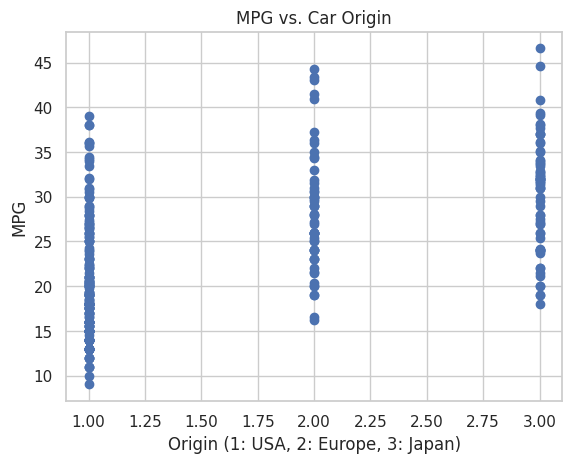

In [47]:
# Creates a scatter plot comparing the 'origin' column (x-axis) against the target 'y_train' (y-axis)
plt.scatter(X_train["origin"], y_train)

# Adds a descriptive title to the top of the chart
plt.title("MPG vs. Car Origin")

# Labels the horizontal x-axis and explains the numeric origin codes
plt.xlabel("Origin (1: USA, 2: Europe, 3: Japan)")

# Labels the vertical y-axis
plt.ylabel("MPG")

# Renders and displays the final plot window on the screen
plt.show()


* **Cars from USA tends to have least of mpg which might be high performance cars**
*  **Cars from japan shows to have high miles per gallon**

#### 4.C.3 Scatterplot of Cylinders Against Miles per Gallon (MPG)

This scatterplot examines the relationship between the number of engine cylinders and vehicle fuel efficiency (`mpg`).

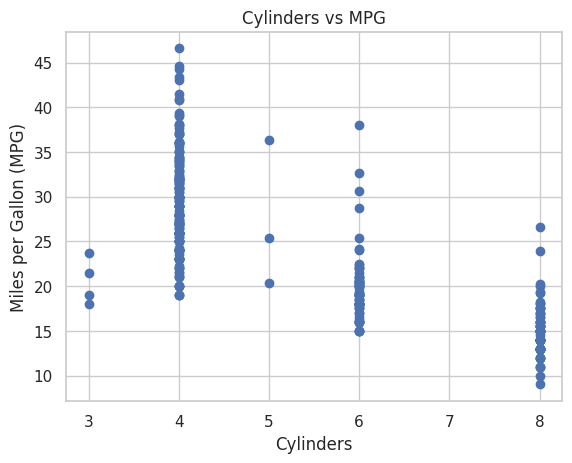

In [48]:
# Create a scatterplot to examine the relationship between cylinders and mpg
plt.scatter(X_train["cylinders"], y_train)

# Label the x-axis and y-axis
plt.xlabel("Cylinders")
plt.ylabel("Miles per Gallon (MPG)")

# Add a title to the plot
plt.title("Cylinders vs MPG")

# Display the scatterplot
plt.show()

* **Cars with 4inline cylinders tend to have high mpg while  v8 have least**

#### 4.C.4 Scatterplot of Displacement Against Miles per Gallon (MPG)

This scatterplot examines the relationship between engine displacement and vehicle fuel efficiency (`mpg`). It helps determine whether changes in engine displacement are associated with changes in fuel consumption efficiency.

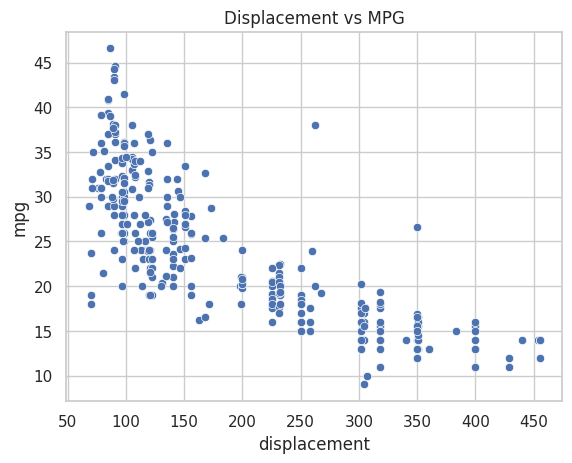

In [49]:
# Create a scatterplot showing the relationship between displacement and mpg
sns.scatterplot(data=X_train, x=X_train["displacement"], y=y_train)

# Add a descriptive title
plt.title("Displacement vs MPG")

# Display the scatterplot
plt.show()

**Cars with higher displacement have least mpg and cars with least displacement higher mpg**

#### 4.C.5 Scatterplot of Horsepower Against Miles per Gallon (MPG)

This scatterplot examines the relationship between engine horsepower and vehicle fuel efficiency (`mpg`). It helps determine whether vehicles with higher horsepower tend to have higher or lower fuel efficiency.

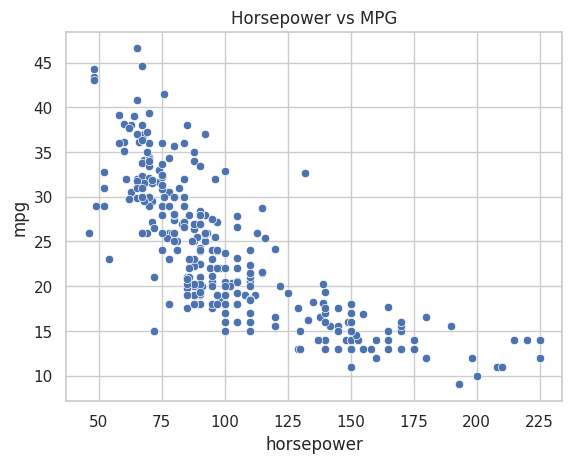

In [50]:
# Create a scatterplot showing the relationship between horsepower and mpg
sns.scatterplot(data=X_train, x=X_train["horsepower"], y=y_train)

# Add a title to the plot
plt.title("Horsepower vs MPG")

# Display the scatterplot
plt.show()

**Cars with higher horsepower have least mpg while least horsepower cars have high mpg**

### 4(d) Multivariate Analysis

Multivariate analysis examines relationships among several variables simultaneously. In this section, a Seaborn pairplot is used to visualize relationships and distributions among selected numerical variables, while a Pearson correlation heatmap is used to measure the strength and direction of linear relationships between numerical variables.

The analysis uses the training dataset only to ensure that the test dataset remains untouched.

#### 4.d.2 Scatterplot of Horsepower Against MPG by Number of Cylinders

This scatterplot examines the relationship between engine horsepower and fuel efficiency (`mpg`), using different colours to represent the number of engine cylinders. It helps compare fuel efficiency across vehicles with different horsepower levels and engine configurations.

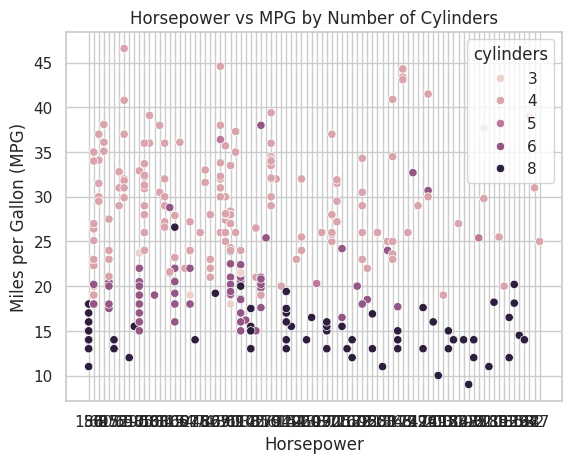

In [14]:
# Create a scatterplot showing horsepower against mpg, coloured by cylinders
sns.scatterplot(
    data=X_train,
    x=X_train["horsepower"],
    y=y_train,
    hue=X_train["cylinders"]
)

# Add a descriptive title
plt.title("Horsepower vs MPG by Number of Cylinders")

# Label the axes
plt.xlabel("Horsepower")
plt.ylabel("Miles per Gallon (MPG)")

# Display the legend and plot
plt.show()

**The trend shows that as the number of cylinder reduces the horsepower the mpg increases**

#### 4.d.3 Pairplot of Training Predictors

A Seaborn pairplot is used to visualize pairwise relationships and individual distributions among the predictor variables in the training dataset. It helps identify patterns, possible correlations and potential relationships between vehicle characteristics.

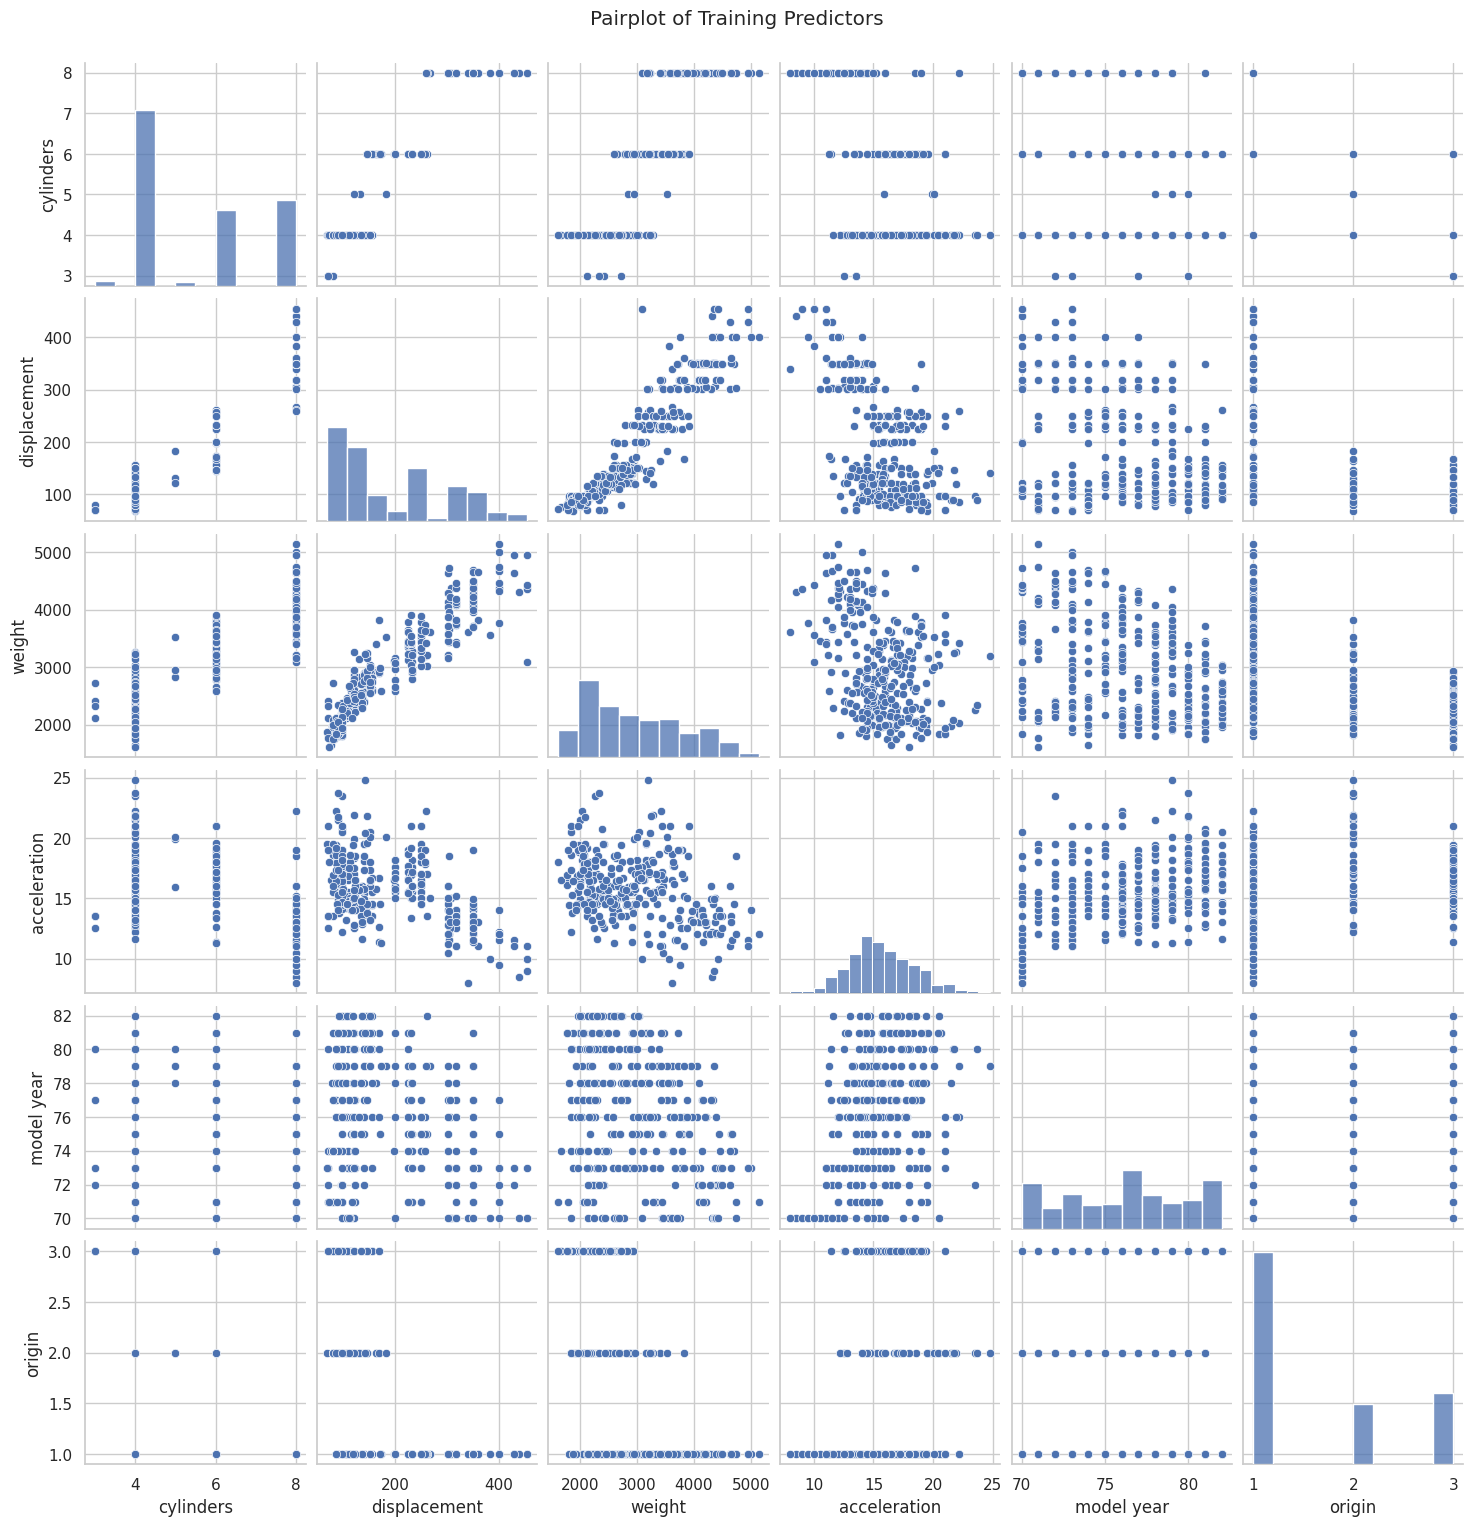

In [15]:
# Generate a pairplot to visualize relationships among training predictors
sns.pairplot(data=X_train)

# Add a descriptive title
plt.suptitle("Pairplot of Training Predictors", y=1.02)

# Display the pairplot
plt.show()

###### Interpretation of Pairplot

1. **Displacement and Weight:** The pairplot shows a strong positive relationship, indicating that vehicles with larger engine displacement generally have greater weight.

2. **Horsepower and Displacement:** A strong positive relationship is observed, suggesting that vehicles with larger engines tend to have higher horsepower.

3. **Weight and Horsepower:** The plot shows a positive relationship, indicating that heavier vehicles generally tend to have higher horsepower.

4. **Acceleration and Horsepower:** A negative relationship is observed, suggesting that vehicles with higher horsepower generally have lower acceleration times.

5. **Distribution of Cylinders:** Most vehicles have four cylinders, while vehicles with six and eight cylinders are also represented.

**Conclusion:** The pairplot reveals important relationships among vehicle characteristics. These patterns can help identify useful predictors of fuel efficiency (`mpg`). However, observed relationships do not necessarily imply causation.

####4.d.4 Pearson Correlation Heatmap of Training Predictors

A Pearson correlation heatmap is used to examine the strength and direction of linear relationships among numerical predictor variables in the training dataset. The correlation coefficients range from -1 to +1, where positive values indicate positive relationships, negative values indicate negative relationships, and values close to zero indicate weak linear relationships.

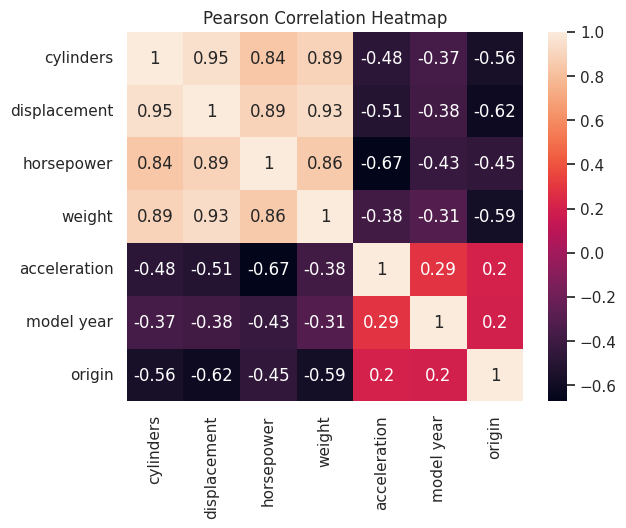

In [53]:
# Calculate Pearson correlation coefficients for numerical training predictors
correlation = X_train.corr(numeric_only=True)

# Create a heatmap to visualize the correlation coefficients
sns.heatmap(correlation, annot=True, cbar=True)

# Add a descriptive title
plt.title("Pearson Correlation Heatmap")

# Display the heatmap
plt.show()

###### Interpretation of Pearson Correlation Heatmap

1. **Cylinders and Displacement:** A very strong positive correlation (0.95) indicates that vehicles with more cylinders generally have larger engine displacement.

2. **Weight and Displacement:** A strong positive correlation (0.93) suggests that vehicles with larger engine displacement tend to be heavier.

3. **Horsepower and MPG:** The correlation between horsepower and MPG is negative (-0.45), indicating that higher horsepower is associated with lower fuel efficiency.

4. **Acceleration and Horsepower:** A negative correlation (-0.67) indicates that higher horsepower is associated with lower acceleration time.

5. **Model Year and MPG:** A weak positive correlation (0.20) suggests a slight positive relationship between model year and vehicle fuel efficiency.

**Conclusion:** The heatmap reveals strong relationships among some vehicle predictors, particularly cylinders, displacement and weight. These relationships may indicate multicollinearity among predictors. However, correlation does not establish causation.

#### 4.d.5Pearson Correlation Heatmap Including the Target Variable

A Pearson correlation heatmap is used to examine the strength and direction of linear relationships among numerical predictors and the target variable (`mpg`). The training predictors and target are first combined into one DataFrame. The correlation coefficients help identify variables that are strongly or weakly associated with fuel efficiency.

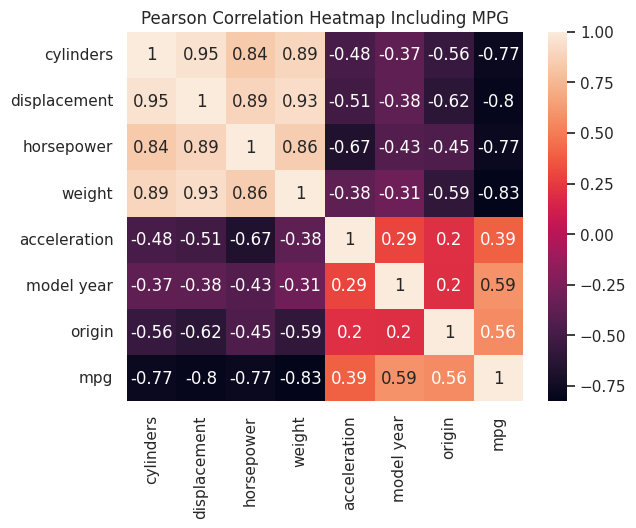

In [54]:
# Combine the training predictors and target variable into one DataFrame
train_comb = pd.concat([X_train, y_train], axis=1)

# Calculate Pearson correlation coefficients for numerical columns
corr = train_comb.corr(numeric_only=True)

# Create a heatmap to display the correlation coefficients
sns.heatmap(corr, annot=True, cbar=True)

# Add a descriptive title
plt.title("Pearson Correlation Heatmap Including MPG")

# Display the heatmap
plt.show()

###### Interpretation of  Correlation Heatmap

1. **Weight and MPG:** A strong negative correlation (-0.83) indicates that heavier vehicles generally have lower fuel efficiency.

2. **Displacement and MPG:** A strong negative correlation (-0.80) suggests that vehicles with larger engine displacement tend to have lower MPG.

3. **Horsepower and MPG:** A strong negative correlation (-0.77) indicates that vehicles with higher horsepower generally have lower fuel efficiency.

4. **Model Year and MPG:** A positive correlation (0.59) suggests that newer vehicles tend to have better fuel efficiency.

5. **Multicollinearity:** Cylinders and displacement have a very strong positive correlation (0.95), indicating that these predictors are highly related.

**Conclusion:** Weight, displacement and horsepower are strongly negatively associated with MPG, while model year has a positive association. However, correlation does not establish causation.

### QUESTION 5: Feature Selection and Leakage-Safe Preprocessing

### 5(a) Feature Selection and Justification

Feature selection involves choosing relevant predictor variables that can help explain and predict vehicle fuel efficiency (`mpg`). Based on the business problem, training-data exploratory analysis and Pearson correlation results, the following four predictors are selected:

1. **Weight:** Selected because it has a strong negative correlation with MPG (-0.83). Heavier vehicles generally tend to have lower fuel efficiency.

2. **Acceleration:** Selected because it has a positive correlation with MPG (0.39). It provides additional information about vehicle performance.

3. **Model Year:** Selected because it has a positive correlation with MPG (0.59). This suggests that newer vehicles generally tend to have better fuel efficiency.


The selected predictors provide a combination of vehicle size, performance, manufacturing period and geographical origin while reducing the risk of multicollinearity.

### 5(b) Missing-Value Treatment and Categorical Encoding

Preprocessing is necessary to prepare the selected predictors for machine learning.

The following preprocessing techniques are applied:

1. **Numerical variables:** Missing values are handled using median imputation for weight, acceleration and model year.
2. **Categorical variable:** Missing values in origin are handled using the most frequent category.
3. **Categorical encoding:** One-Hot Encoding is applied to origin to convert its categories into numerical features suitable for regression.

A ColumnTransformer is used to organize the preprocessing operations. All preprocessing operations are fitted using the training data only and then applied to the testing data. This prevents data leakage.

##QUESTION 6: Multiple Linear Regression and Model Evaluation

### 6(a) Baseline Model and Multiple Linear Regression

A baseline model is first developed using the mean of the training target variable (`mpg`). It provides a reference point for evaluating the performance of the Multiple Linear Regression model.

A Multiple Linear Regression model is then trained using the prepared training data from Question 5. The model uses weight, acceleration, model year and the encoded origin categories to predict vehicle fuel efficiency (`mpg`).

The model learns coefficients for the selected predictors and an intercept, which together form the fitted regression equation.

### 6.a.1 Defining the Data Preprocessing Pipelines

The numerical, categorical, and other numerical features are assigned to separate preprocessing pipelines to ensure that each group receives the appropriate transformation.

- **Numerical features:** `displacement` and `weight` are processed by replacing missing values with the median and standardizing the values using `StandardScaler`.
- **Log-transformed features:** `horsepower` and `acceleration` have missing values replaced with the median before applying a logarithmic transformation using `np.log1p`.
- **Categorical features:** `cylinders`, `model year`, and `origin` have missing values replaced with the most frequent value and are converted into numerical representations using one-hot encoding.

Finally, `ColumnTransformer` combines the three pipelines into one preprocessing object. This ensures that all selected features are processed consistently before being passed to the regression model.

In [55]:
# Define numerical features that will be imputed and scaled
num = ["displacement", "weight"]

# Define numerical features that will be imputed and log-transformed
out = ["horsepower", "acceleration"]

# Define categorical features to be imputed and one-hot encoded
cat = ["cylinders", "model year", "origin"]

# Create a pipeline for numerical features using median imputation and standardization
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())
])

# Create a pipeline for other numerical features using median imputation and log transformation
out_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='median')),
    ("log", FunctionTransformer(np.log1p))
])

# Create a pipeline for categorical features using mode imputation and one-hot encoding
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encode", OneHotEncoder(sparse_output=False))
])

# Combine all preprocessing pipelines using ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num),
    ("cat", cat_pipeline, cat),
    ("out", out_pipeline, out)
])

### 6.a.2 Creating the Baseline Regression Model

A machine learning pipeline is created to combine data preprocessing with a baseline regression model. The `DummyRegressor` uses the mean strategy to establish a simple reference model for comparison with more advanced regression models.

The `TransformedTargetRegressor` applies a logarithmic transformation (`log1p`) to the target variable (`mpg`) before training. After prediction, the `expm1` function converts the predicted values back to the original MPG scale.

This provides a baseline for evaluating how well the other regression models predict fuel efficiency.

In [56]:
# Create a pipeline that applies preprocessing and fits a baseline regression model
dummy = Pipeline([
    # Apply the defined preprocessing steps
    ("preprocessor", preprocessor),

    # Predict the mean of the training target variable
    ("model", DummyRegressor(strategy='mean'))
])

# Create a transformed target regressor using logarithmic transformation
model1 = TransformedTargetRegressor(
    # Use the baseline pipeline as the regression model
    regressor=dummy,

    # Apply log1p transformation to the target variable
    func=np.log1p,

    # Convert predictions back to the original target scale
    inverse_func=np.expm1
)

### 6.a.2.1 Training the Baseline Model

The baseline model is fitted using the training dataset (`X_train` and `y_train`). During this step, the preprocessing operations are learned from the training data, and the baseline model is trained to establish a reference for evaluating the performance of more advanced regression models. The test dataset remains untouched during training.

In [57]:
# Train the transformed baseline model using the training data
model1.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('scaler',
                                                                                                        StandardScaler())]),
                                                                                       ['displacement',
                                                                                        'weight']),
                                                                                      ('cat',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('encode',
                                                                                                        OneHotEncoder(sparse_output=False))]),
                                                                                       ['cylinders',
                                                                                        'model '
                                                                                        'year',
                                                                                        'origin']),
                                                                                      ('out',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('log',
                                                                                                        FunctionTransformer(func=<ufunc 'log1p'>))]),
                                                                                       ['horsepower',
                                                                                        'acceleration'])])),
                                                     ('model',
                                                      DummyRegressor())]))

###6.a.2.2 Making Predictions Using the Baseline Model

The trained baseline model is used to predict the fuel efficiency (`mpg`) of vehicles in the testing dataset (`X_test`). The predicted values are stored in `y_pred1` and will be compared with the actual MPG values to evaluate the model's predictive performance.

In [58]:
# Use the trained baseline model to predict MPG values for the test dataset
y_pred1 = model1.predict(X_test)

In [ ]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred1)}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, y_pred1))}")
print(f"R-squared: {r2_score(y_test, y_pred1)}")

Mean Absolute Error: 5.985992403500504
Root Mean Squared Error: 7.374894434764821
R-squared: -0.011580162839487151


### 6.a.5 Creating the Multiple Linear Regression Model

A machine learning pipeline is created by combining the preprocessing steps with a `LinearRegression` model. The preprocessing pipeline handles missing values, feature scaling, logarithmic transformation, and categorical encoding before the data is passed to the regression algorithm.

The `TransformedTargetRegressor` applies a logarithmic transformation (`np.log1p`) to the target variable (`mpg`) during model training. It then uses the inverse transformation (`np.expm1`) to convert predictions back to the original MPG scale.

This model will be trained and evaluated to determine how well the selected vehicle features explain and predict fuel efficiency.

In [59]:
# Create a pipeline that applies preprocessing and fits a Linear Regression model
lr = Pipeline([
    # Apply the defined preprocessing steps
    ("preprocessor", preprocessor),

    # Fit the multiple linear regression model
    ("model", LinearRegression())
])

# Create a transformed target regressor using logarithmic transformation
model = TransformedTargetRegressor(
    # Use the linear regression pipeline as the regression model
    regressor=lr,

    # Apply log1p transformation to the target variable
    func=np.log1p,

    # Convert predictions back to the original MPG scale
    inverse_func=np.expm1
)

### 6.a.5.1 Training the Multiple Linear Regression Model

The multiple linear regression model is trained using the training dataset (`X_train` and `y_train`). During training, the preprocessing steps are fitted on the training features, and the regression algorithm learns the relationship between the selected predictors and the target variable (`mpg`).

The logarithmic transformation is also applied to the target variable during training. The test dataset remains untouched until model evaluation.

In [60]:
# Train the multiple linear regression model using the training data
model.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('scaler',
                                                                                                        StandardScaler())]),
                                                                                       ['displacement',
                                                                                        'weight']),
                                                                                      ('cat',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('encode',
                                                                                                        OneHotEncoder(sparse_output=False))]),
                                                                                       ['cylinders',
                                                                                        'model '
                                                                                        'year',
                                                                                        'origin']),
                                                                                      ('out',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('log',
                                                                                                        FunctionTransformer(func=<ufunc 'log1p'>))]),
                                                                                       ['horsepower',
                                                                                        'acceleration'])])),
                                                     ('model',
                                                      LinearRegression())]))

### 6.a.5.2 Making Predictions Using the Multiple Linear Regression Model

The trained multiple linear regression model is used to predict the fuel efficiency (`mpg`) of vehicles in the testing dataset (`X_test`). The predicted values are stored in `y_pred` and will be compared with the actual MPG values (`y_test`) to assess the model's predictive performance.

### 6.b.1 Evaluating the Baseline Model

The baseline model is evaluated using three regression performance metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between the actual and predicted MPG values. Lower values indicate better predictions.
- **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors. It penalizes larger errors more heavily.
- **R-squared (R²):** Measures how much variation in the target variable is explained by the model. A value closer to 1 indicates better performance, while a negative value indicates performance worse than predicting the test-set mean.

These metrics establish a baseline against which the performance of the multiple linear regression model can be compared.

In [61]:
# Use the trained multiple linear regression model to predict MPG values for the test dataset
y_pred = model.predict(X_test)

### 6.b.2 Evaluating the Multiple Linear Regression Model

The multiple linear regression model is evaluated using three performance metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted MPG values. Lower values indicate better predictions.
- **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors. It gives greater weight to larger errors.
- **R-squared (R²):** Measures the proportion of variation in MPG explained by the model. Values closer to 1 indicate a better fit.

The results are compared with those of the baseline model to determine whether multiple linear regression provides better predictive performance.

In [62]:
# Calculate and display the Mean Absolute Error (MAE)
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")

# Calculate and display the Root Mean Squared Error (RMSE)
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, y_pred))}")

# Calculate and display the R-squared (R²) score
print(f"R-squared: {r2_score(y_test, y_pred)}")

Mean Absolute Error: 1.7942133401352638
Root Mean Squared Error: 2.3458218908847654
R-squared: 0.8976521421178395


### 6.c.1 Actual vs Predicted MPG Values

A scatter plot is used to compare the actual MPG values with the values predicted by the multiple linear regression model. The red dashed line represents perfect predictions, where predicted values equal actual values.

Points closer to the red line indicate more accurate predictions, while points farther away represent larger prediction errors. This visualization helps assess how well the model predicts vehicle fuel efficiency on the test dataset.

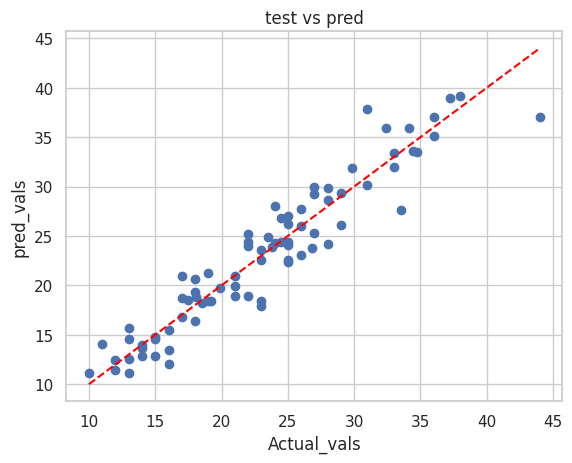

In [63]:
# Create a scatter plot comparing actual and predicted MPG values
plt.scatter(y_test, y_pred)

# Label the x-axis and y-axis
plt.xlabel("Actual_vals")
plt.ylabel("pred_vals")

# Determine the minimum and maximum values for the reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

# Add a red dashed reference line representing perfect predictions
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color="red")

# Add a title and display the plot
plt.title("test vs pred")
plt.show()

### 6.c.2 Residuals vs Actual MPG Values

Residuals are calculated by subtracting predicted MPG values from actual MPG values. The scatter plot helps examine the prediction errors and identify possible patterns.

- Residuals close to zero indicate more accurate predictions.
- Positive residuals indicate that the model underestimated MPG.
- Negative residuals indicate that the model overestimated MPG.
- A random distribution of residuals around zero suggests that the model captures the relationship reasonably well.

The plot can also reveal patterns that may indicate non-linearity or other limitations in the model.

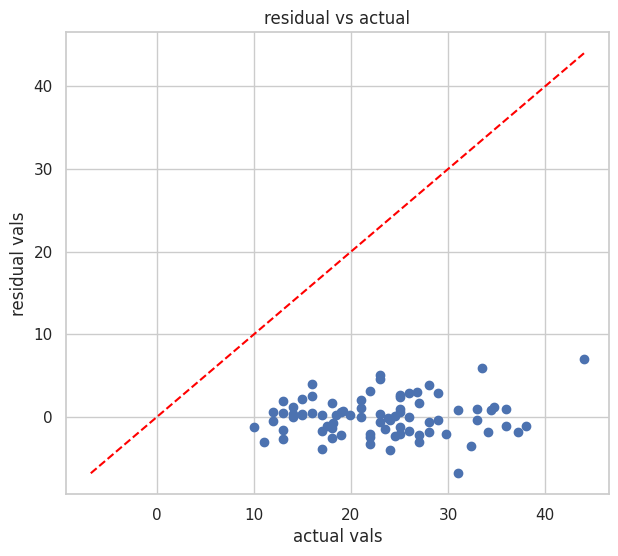

In [64]:
# Set the figure size for better visualization
plt.figure(figsize=(7,6))

# Calculate residuals as the difference between actual and predicted MPG values
residual = y_test - y_pred

# Create a scatter plot of actual MPG values against residuals
plt.scatter(y_test, residual)

# Label the x-axis and y-axis
plt.xlabel("actual vals")
plt.ylabel("residual vals")

# Determine the minimum and maximum values for the reference line
min_val = min(y_test.min(), residual.min())
max_val = max(y_test.max(), residual.max())

# Add a red dashed reference line
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color="red")

# Add a title and display the plot
plt.title("residual vs actual")
plt.show()

## QUESTION 7: Prediction, Conclusions and Communication

### a) Comparing Predicted and Actual MPG Values

The first six records from the test dataset are displayed to compare the MPG values predicted by the multiple linear regression model with the actual observed values.

The error is calculated by subtracting the predicted MPG from the actual MPG. Positive errors indicate underprediction, while negative errors indicate overprediction. The absolute size of the error shows how far the prediction is from the observed value.

In [66]:
# Combine the first six predicted and actual MPG values into one DataFrame
view = pd.DataFrame({
    "Predicted MPG": y_pred[:6],
    "Actual MPG": y_test[:6]
})

# Calculate the prediction error
view["Error"] = view["Actual MPG"] - view["Predicted MPG"]

# Display the comparison
display(view)

,Predicted MPG,Actual MPG,Error
198,33.408,33.000,-0.408
396,29.809,28.000,-1.809
33,21.209,19.000,-2.209
208,15.686,13.000,-2.686
93,12.832,14.000,1.168
84,25.328,27.000,1.672


### (b) Non-Technical Summary

**Business Question:**  
The project aimed to develop a regression model that predicts vehicle fuel efficiency (MPG) using characteristics such as weight, displacement, horsepower, acceleration, cylinders, model year and origin.

**Major EDA Findings:**  
Exploratory Data Analysis revealed that vehicle weight, displacement and horsepower generally have negative relationships with fuel efficiency. Heavier vehicles tend to consume more fuel, while newer model years generally show improvements in fuel efficiency.

**Model Performance:**  
The multiple linear regression model achieved a Mean Absolute Error (MAE) of [insert MAE], a Root Mean Squared Error (RMSE) of [insert RMSE] and an R-squared value of [insert R²]. These results indicate that the model can explain approximately [R² × 100]% of the variation in fuel efficiency. Compared with the baseline model, the multiple linear regression model [performed better/performed worse].

**Model Limitation:**  
The model assumes a linear relationship between the predictors and fuel efficiency. However, some relationships may be non-linear, which could limit prediction accuracy.

**Practical Recommendation:**  
Vehicle buyers should consider factors such as weight, engine displacement and horsepower when choosing fuel-efficient vehicles. Manufacturers and other stakeholders can also use the model as an initial decision-support tool when assessing vehicle fuel efficiency. Further improvements could be achieved by testing additional predictors and more advanced regression techniques.

## Dataset Source and Modifications

The dataset used in this project is the **Auto MPG dataset**, obtained from the following sources:

1. **CSV Dataset:** [Auto MPG CSV – Hugging Face](https://huggingface.co/datasets/scikit-learn/auto-mpg/blob/main/auto-mpg.csv)
2. **Original Dataset and Documentation:** [UCI Machine Learning Repository – Auto MPG](https://archive.ics.uci.edu/dataset/9/auto-mpg)

### Data Modifications

The downloaded dataset was subjected to initial data quality assessment and cleaning before analysis. The following modifications were made:

- The `horsepower` column was converted to a numeric data type.
- Six placeholder values (`?`) in the `horsepower` column were converted to missing values (`NaN`).
- No exact duplicate records were identified.
- No records with missing target values (`mpg`) were found.
- Missing predictor values were retained and handled through imputation during model preprocessing.
- The `car name` column was excluded from the predictors because it serves as a vehicle identifier rather than a numerical explanatory feature.

The original dataset structure was preserved, and preprocessing operations were incorporated into machine learning pipelines to ensure consistent data preparation and prevent data leakage.

## Conclusion

This project applied data analytics and machine learning techniques to predict vehicle fuel efficiency (`mpg`) using the Auto MPG dataset. Exploratory Data Analysis revealed important relationships between vehicle characteristics and fuel efficiency, particularly the negative relationship between vehicle weight, engine displacement and MPG.

A baseline regression model and a multiple linear regression model were developed and evaluated using MAE, RMSE and R-squared. The evaluation results provided a basis for assessing the predictive performance of the models.

Although the regression model provides useful estimates of vehicle fuel efficiency, its predictions may be limited by the assumption of linear relationships and the characteristics of the available dataset. Further improvements could involve testing non-linear regression techniques and incorporating additional vehicle characteristics.

Overall, the project demonstrates how regression analysis can support vehicle fuel-efficiency assessment and informed decision-making.